C:\Users\Admin\AppData\Local\Temp\ipykernel_23308\4199113060.py:185: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


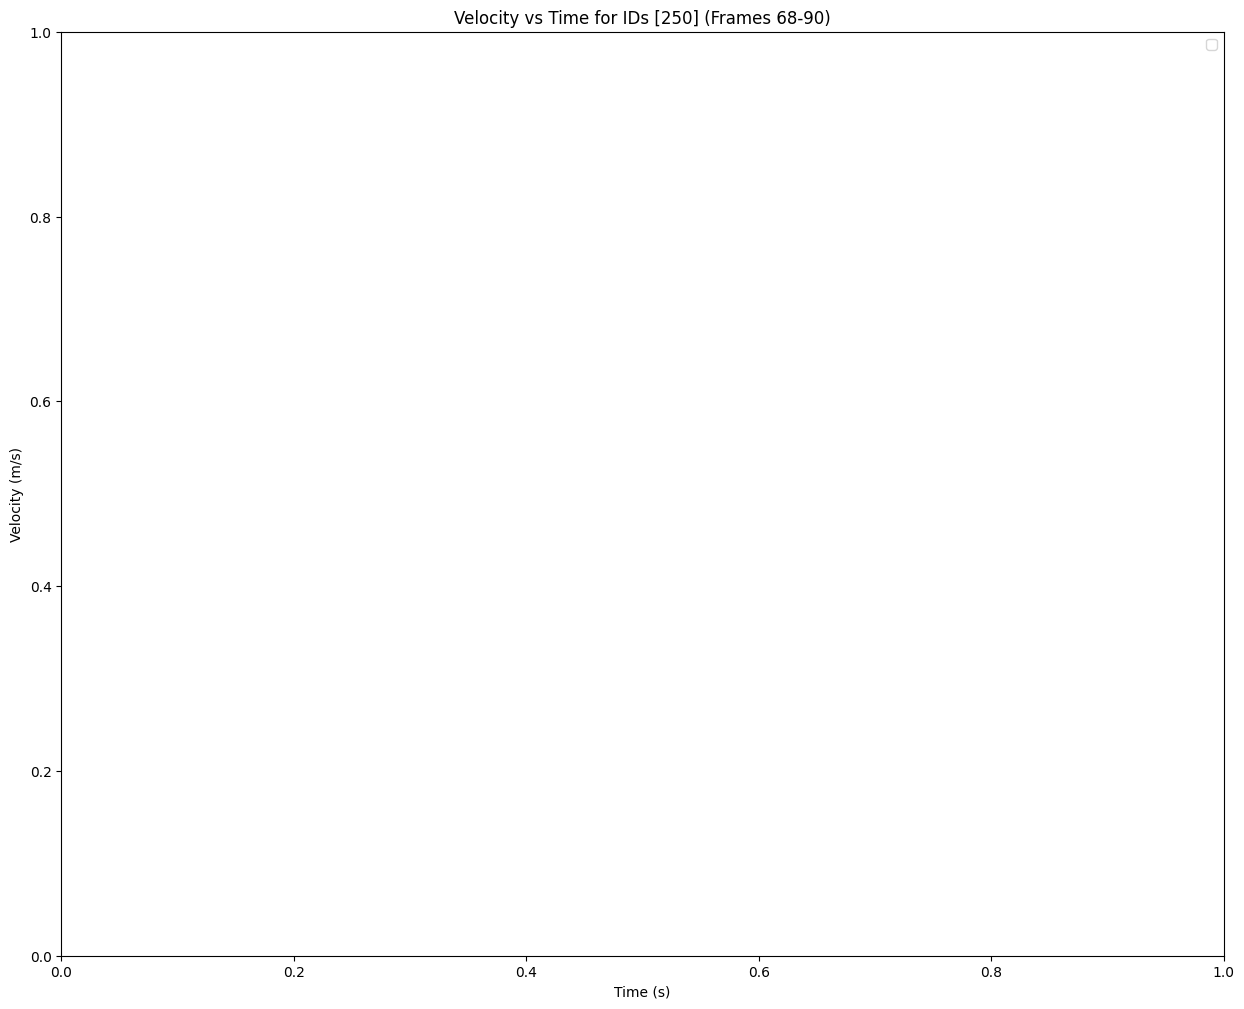

In [7]:
import cv2
import numpy as np
from tracker import EuclideanDistTracker
import math
import matplotlib.pyplot as plt
import csv
import pandas as pd
import time
from collections import deque
from paths import OUTPUT, RESULTS, data_file   # project folders (see paths.py)

#Data for the Velocity
fps = 500
frame_width_px = 1280
frame_height_py= 1024  

real_width_A = 69.441                                           # In cm
real_height_A = 55.531  

meters_per_pixel_x = (real_width_A/100)/ frame_width_px
meters_per_pixel_y = (real_height_A/100)/frame_height_py

#We have enlisted some tracking ID's that we need to track. We store the values of the centeroids and frame indices in the disct to get them later.
Tracking_id = range(1,1000)
centroids_values = {tid: [] for tid in Tracking_id}
frame_indices_values = {tid: [] for tid in Tracking_id}
area_boul={tid:[] for tid in Tracking_id}

Tracker_ejecta= EuclideanDistTracker()                                         #Create tracker object( file in the same location as the py file)

video= cv2.VideoCapture(data_file("Merengues bowl1_C001S0001.avi"))
# object_d=cv2.createBackgroundSubtractorMOG2(1000,40,False)             #Detection of the objects 
object_d= cv2.createBackgroundSubtractorKNN(1000,400, False)
c=0
frame_count=0
fourcc=cv2.VideoWriter_fourcc(*'XVID')
out=cv2.VideoWriter(str(OUTPUT / "Video_TV.avi"),fourcc,5,(1280,1024),True)
while video.isOpened():
    r, frame= video.read()
    if r==True:
        h,w, _= frame.shape
        roi_gray= cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        roi_gray=cv2.GaussianBlur(frame,(3,3),0)
        mask= object_d.apply(frame)           #reason for the Roi is that the mask is considered for the subrastraction method of the ROI.

        #Cleaning the video for the detection of Boulder.
        _, mask= cv2.threshold(mask, 200, 255, cv2.THRESH_BINARY)

        mask= cv2.medianBlur(mask, 5)
        kernel_o = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
        kernel_c= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(11,11))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_o, iterations=1) 
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel_c,iterations=1)
        # mask = cv2.dilate(mask, kernel, iterations=1)  # fill gaps
        # edges=cv2.Canny(roi_gray,60,180,L2gradient=True)
        # edges= cv2.dilate(edges,kernel,iterations=1)
        # mask= cv2.bitwise_and(mask,edges)

        contours, _= cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
        detection=[]
        for cnt in contours:
            area= cv2.contourArea(cnt)                                                             #To determine the area of the countour that helps in the area selection for the oebject detection
            if area<20 or area>20000:
                continue     
            x,y,w,h= cv2.boundingRect(cnt)
            hull=cv2.convexHull(cnt)
            hull_area= cv2.contourArea(hull) if len(hull)>=3 else 1.0
            solidity = float(area)/hull_area if hull_area>0 else 0
            rect_area= float(w*h)
            extent= float(area)/rect_area if rect_area>0 else 0

            if solidity<0.65:
                continue
            if extent<0.2:
                continue

            detection.append([x,y,w,h])
            cv2.drawContours(frame,[cnt],-1,(0,255,0),1)

# Detecting the object and checks the new position with the previous position of the frame.
        boxes_ids = Tracker_ejecta.update(detection)
        for x, y, w, h, id in boxes_ids:
            if id not in Tracking_id:
                continue
            x,y,w,h=int(x),int(y),int(w),int(h)
            cx = x + w/2.0
            cy = y + h/2.0
            cv2.rectangle(frame, (x, y), (x+w, y+h), (0,255,0), 1)
            cv2.putText(frame, str(id), (x, y-10), cv2.FONT_HERSHEY_PLAIN, 1, (255,0,0), 1)
            centroids_values[id].append((cx, cy))
            # print(f"ID:{id},Centroid:({cx},{cy})")
            frame_indices_values[id].append(frame_count)
            area_box=w*h
            area_boul[id].append(area_box)
        c=c+1
        frame_count+=1
        cv2.imshow("Mask", mask)
        cv2.imshow("Window", frame)
        # cv2.imwrite(str(RESULTS / "TV" / "Mask" / "mask")+str(c)+".png",mask)
        # cv2.imwrite(str(RESULTS / "TV" / "BGR" / "frame")+str(c)+".png",frame)
        out.write(frame)
        if cv2.waitKey(10) & 0xff==ord("z"):
            break


video.release()
out.release()
cv2.destroyAllWindows()

# Velocity, distance, time and frame determination of the individual ID's

distances_dict = {tid: [] for tid in Tracking_id}           # Making th dict to store the value of the data for each ID.
average_speed = {tid: [] for tid in Tracking_id}
time_dict = {tid: [] for tid in Tracking_id}
vx_dict={tid:[] for tid in Tracking_id}
vy_dict={tid:[] for tid in Tracking_id}
rows=[]

for tid in Tracking_id:
    centroids = centroids_values[tid]
    frames = frame_indices_values[tid]
    areas=area_boul[tid] 

    if len(centroids) < 2:                  # To check that we have atleast two data for the centroids for the velocity determination
        continue

    for i in range(1, len(centroids)):
        cx1, cy1 = centroids[i-1]
        cx2, cy2 = centroids[i]

        # Pixel differences
        dx_px = cx2 - cx1
        dy_px = cy2 - cy1

        # Convert to meters
        dx_m = dx_px * meters_per_pixel_x
        dy_m = dy_px * meters_per_pixel_y

        distance = math.hypot(dx_m, dy_m)
        dt = (frames[i] - frames[i-1]) / fps

        if dt > 0:
            vx=dx_m/dt
            vy=(dy_m/dt)
            speed = math.hypot(vx,vy)
            distance=math.hypot(dx_m,dy_m)
            t_sec=(frames[i]/(fps))
            From_area=areas[i-1]
            to_area=areas[i]
            distances_dict[tid].append(distance)
            vx_dict[tid].append(vx)
            vy_dict[tid].append(vy)
            average_speed[tid].append(speed)
            time_dict[tid].append(t_sec)
            rows.append([tid, f"{frames[i-1]}",f"{frames[i]}",f"{From_area:.2f}",f"{cx1:.2f}",f"{cy1:.2f}",f"{to_area:.2f}",f"{cx2:.2f}",f"{cy2:.2f}",f"{dx_m:.4f}",f"{dy_m:.4f}",f"{distance:.4f}", f"{t_sec:.4f}", f"{vx:.2f}",f"{vy:.2f}",f"{speed:.2f}"])
            
timestamp=time.strftime("%Y%m%d_%H%M%S")
location=str(RESULTS / "excel" / "topview" / f"Data_Top_view{timestamp}.csv")

with open(location,mode='w', newline='') as f:
    writer=csv.writer(f,delimiter=';')
    writer.writerow(["ID","Frame_From","Frame_To","Area_1","Centroid_X1","Centroid_Y1","Area_2","Centroid_X2","Centroid_Y2","dx_m","dy_m","Distance(m)", "Time(s)", "vx(m/s)","vy(m/s)","speed(m/s)"])
    writer.writerows(rows)

stored_val = pd.read_csv(location, sep=";")
stored_val["ID"] = stored_val["ID"].astype(int)
stored_val["speed(m/s)"] = stored_val["speed(m/s)"].astype(float)
stored_val["vx(m/s)"] = stored_val["vx(m/s)"].astype(float)
stored_val["vy(m/s)"] = stored_val["vy(m/s)"].astype(float)
stored_val["Time(s)"] = stored_val["Time(s)"].astype(float)

frame_min, frame_max = 68,90
t_min,t_max= frame_min/fps, frame_max/fps
ids_to_plot = [250]

plt.figure(figsize=(15, 12))
for tid in ids_to_plot:
    df_filtered = stored_val[(stored_val["ID"] == tid) & (stored_val["Time(s)"] >= t_min) & (stored_val["Time(s)"] <= t_max)]
    if not df_filtered.empty:
        plt.plot(df_filtered["Time(s)"], df_filtered["Velocity(m/s)"], marker='o', linestyle='-', label=f"ID {tid}")

plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title(f"Velocity vs Time for IDs {ids_to_plot} (Frames {frame_min}-{frame_max})")
plt.legend()
plt.show()




In [6]:
import cv2
import numpy as np
import math
from paths import RESULTS   
image= cv2.imread(r"D:\Python Code\Boulder Detection Project\Data\Frames1023.png",1)
overlay=image.copy()
cv2.ellipse(overlay,(997,450),(180,180),0,90,270,(128,0,128),-1,cv2.LINE_AA)

step1=cv2.addWeighted(overlay,0.3,image,0.7,0,image)

outer_arc= cv2.ellipse2Poly((992,455),(310,310),0,90,270,1)
inner_arc=cv2.ellipse2Poly((997,450),(180,180),0,90,270,1)

ring_contour= np.vstack([outer_arc,inner_arc[::-1]])

overlay2= step1.copy()
cv2.fillPoly(overlay2,[ring_contour],(252, 136, 3),lineType=cv2.LINE_AA)
output= cv2.addWeighted(overlay2,0.3,step1,0.7,0)


outer_arc_1= cv2.ellipse2Poly((992,455),(530,500),0,90,270,1)
inner_arc_1= cv2.ellipse2Poly((992,455),(310,310),0,90,270,1)

ring_contour_1= np.vstack([outer_arc_1,inner_arc_1[::-1]])

overlay3= output.copy()
cv2.fillPoly(overlay3,[ring_contour_1],(3, 252, 15),lineType=cv2.LINE_AA)
final=cv2.addWeighted(overlay3,0.3,output,0.7,0)

overlay4=final.copy()
cv2.circle(final,(680,200),25,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(831,776),25,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(720,404),25,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(441,327),8,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(380,342),6,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(398,324),4,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(499,330),16,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(457,214),3,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(891,1016),30,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(651,622),18,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(374,876),15,(128,0,128),-1,cv2.LINE_AA)
cv2.circle(final,(901,286),25,(128,0,128),-1,cv2.LINE_AA)

cv2.line(final,(680,200),(894,354),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(831,776),(945,525),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(831,776),(945,525),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(831,776),(945,525),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(831,776),(945,525),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(891,1016),(983,558),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(720,404),(871,429),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(651,622),(925,451),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(901,286),(946,371),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(374,876),(925,451),(0,0,255),2,cv2.LINE_4)
cv2.line(final,(499,330),(908,401),(0,0,255),2,cv2.LINE_4)


cv2.circle(final,(972,421),10,(0,255,0),-1,cv2.LINE_AA)
cv2.line(final,(972,421),(1140,420),(0,0,255),2,cv2.LINE_AA)
cv2.putText(final,"Point of Impact", (1150,420),cv2.FONT_HERSHEY_COMPLEX,0.4,(0,255,0),1,cv2.LINE_4,False)

cv2.putText(final,"4",(817,790),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"1",(707,417),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"5",(640,630),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"7",(882,300),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"3",(660,212),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"5",(346,900),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)
cv2.putText(final,"2",(414,370),cv2.FONT_HERSHEY_COMPLEX,0.8,(0,255,0),2,cv2.LINE_4,False)

final_02= cv2.addWeighted(overlay4,0.3,final,0.7,0)

cv2.imshow("Window", final_02)
# cv2.imwrite(str(RESULTS / "Image.png"),final_02)
cv2.waitKey(0)
cv2.destroyAllWindows()

